In [197]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from components.feature_extractor.main import FeatureExtractor
from PIL import Image
import numpy as np


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


[{'boxes': tensor([[841.1395, 308.5628, 884.7519, 402.4784],
        [829.3328, 332.8124, 852.5402, 377.4112],
        [828.9751, 323.4282, 858.0568, 400.1181],
        [830.4393, 339.3757, 850.2458, 365.2162],
        [830.7049, 336.0345, 852.0419, 364.6952],
        [829.1661, 342.9727, 840.2206, 363.2748],
        [858.9302, 327.8606, 881.2413, 355.0500],
        [828.6853, 340.2350, 843.8092, 364.8034],
        [831.4788, 365.2209, 847.4737, 378.4801]]), 'labels': tensor([ 1,  1,  1, 27, 31, 27, 27, 31, 33]), 'scores': tensor([0.9968, 0.7959, 0.5505, 0.4682, 0.2847, 0.2247, 0.0966, 0.0765, 0.0555])}]
(830, 1030)


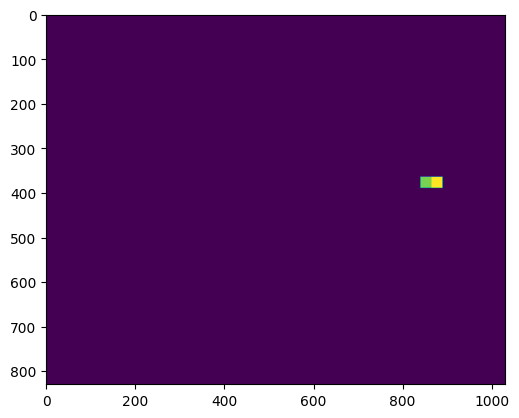

In [198]:
# sorry, this was done on a windows machine
image = Image.open("..\\..\\Datasets\\People\\images\\U0121_1RTE.jpg").convert("RGB")


feature_extractor = FeatureExtractor(np.array([image]), 'person', { 'stride': 25 })
p_maps = feature_extractor.get_foveal_p_map()
plt.imshow(p_maps[0])

In [201]:
features = feature_extractor.extract()
for k, v in features.items():
    print(k, v.shape)


0 torch.Size([1, 256, 208, 258])
1 torch.Size([1, 256, 104, 129])
2 torch.Size([1, 256, 52, 65])
3 torch.Size([1, 256, 26, 33])
pool torch.Size([1, 256, 13, 17])


825


((33,), (25,))

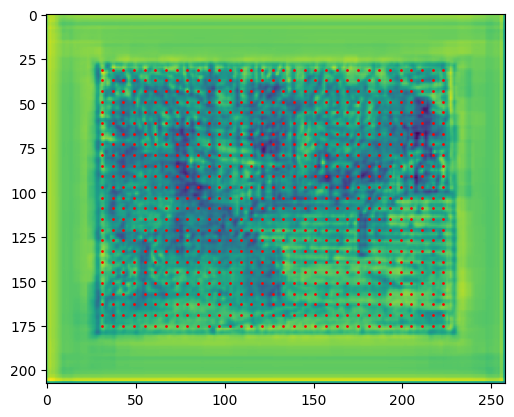

In [202]:
feature_columns = features["0"]
stride = 25 // 4
sample_size = 25
padding = 115 // 4
dist = sample_size // 2

grid_locations = np.array(
    [
        (x + stride // 2, y + stride // 2)
        for x in range(padding, feature_columns.shape[3] - padding - stride, stride)
        for y in range(padding, feature_columns.shape[2] - padding - stride, stride)
    ]
)

# testing grid on one channel of the features
print(len(grid_locations))
plt.scatter(grid_locations[:, 0], grid_locations[:, 1], c="r", s=1)
plt.imshow(feature_columns[0, 0, :, :].detach().numpy())
np.unique(grid_locations[:, 0]).shape, np.unique(grid_locations[:, 1]).shape

In [152]:
# testing shapes of grid locations
max_x, max_y = grid_locations.max(axis=0)
min_x, min_y = grid_locations.min(axis=0)
print(min_x, max_x, min_y, max_y)
print(feature_columns.shape)
print(208 * 4, 258 * 4)

np.unique(grid_locations[:, 0]).shape, np.unique(grid_locations[:, 1]).shape

31 217 31 169
torch.Size([1, 256, 208, 258])
832 1032


((32,), (24,))

(1030, 830)
768


((32,), (24,))

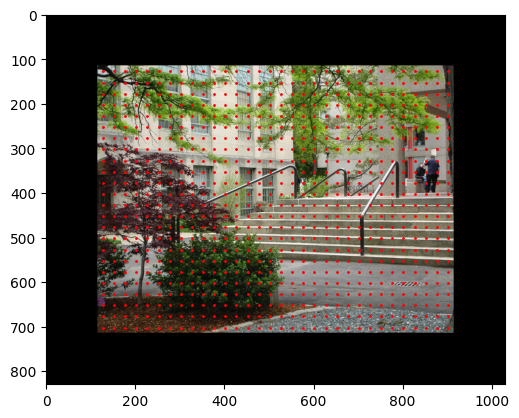

In [146]:
from torchvision.transforms import Pad

padding = 115
stride = 25

padder = Pad(padding=padding, fill=0)
padded_image = padder(image)
plt.imshow(padded_image)

print(padded_image.size)

grid_locations = np.array(
    [
        (x + stride // 2, y + stride // 2)
        for x in range(padding, padded_image.size[0] - padding, stride)
        for y in range(padding, padded_image.size[1] - padding, stride)
    ]
)

print(len(grid_locations))

plt.scatter(grid_locations[:, 0], grid_locations[:, 1], c="r", s=1)
np.unique(grid_locations[:, 0]).shape, np.unique(grid_locations[:, 1]).shape


In [187]:
from components.max_pooler import eccentricity_pooler

results = eccentricity_pooler(feature_columns, stride)

len(results)

torch.Size([1, 256, 208, 258]) 6


4

In [195]:
len(results[0][0])
tens = results[3][0]

tens.shape

torch.Size([256])